# Revision: SQL, Handling Imbalanced Data, and Transformers


## Part 1: SQL Revision


### SQL Command Categories

- SQL commands split into five categories based on what they do
- DDL, Data Definition Language: defines and changes database structure
- DML, Data Manipulation Language: changes the data inside tables
- DQL, Data Query Language: retrieves data, this is where SELECT lives
- DCL, Data Control Language: manages permissions and access
- TCL, Transaction Control Language: manages groups of operations as one unit


### DDL: Data Definition Language

- Defines and changes structure, not the data itself
- CREATE builds a new table, database, or other object
- ALTER changes an existing table's structure, adding or modifying columns
- DROP permanently deletes a table or database, structure and data both
- TRUNCATE removes all rows from a table but keeps its structure

```sql
CREATE TABLE employees (
    id INT PRIMARY KEY,
    name VARCHAR(100),
    department VARCHAR(50),
    salary DECIMAL(10, 2)
);

ALTER TABLE employees ADD COLUMN hire_date DATE;

DROP TABLE employees;
```


### DML: Data Manipulation Language

- Adds, changes, or removes the actual rows inside a table
- INSERT adds new rows
- UPDATE modifies existing rows
- DELETE removes rows

```sql
INSERT INTO employees (id, name, department, salary)
VALUES (1, 'Sara Ahmed', 'Engineering', 65000);

UPDATE employees
SET salary = 70000
WHERE id = 1;

DELETE FROM employees
WHERE department = 'Engineering';
```


### DQL: Data Query Language

- Retrieves data without changing it
- SELECT is the command, but it comes with several clauses
- WHERE filters individual rows before any grouping happens
- GROUP BY collects rows into groups that share a column value
- HAVING filters groups after aggregation, WHERE cannot do this
- ORDER BY sorts the final result

```sql
SELECT department, AVG(salary) AS avg_salary
FROM employees
WHERE hire_date > '2020-01-01'
GROUP BY department
HAVING AVG(salary) > 60000
ORDER BY avg_salary DESC;
```


### JOIN Types

- A JOIN combines rows from two or more tables using a related column
- INNER JOIN keeps only rows that match in both tables
- LEFT JOIN keeps all rows from the left table, unmatched right-side columns become NULL
- RIGHT JOIN is the mirror of LEFT JOIN, all rows from the right table
- FULL OUTER JOIN keeps all rows from both tables, matched or not

```sql
SELECT e.name, d.department_name
FROM employees e
LEFT JOIN departments d ON e.department_id = d.id;
```


### NULL Handling

- NULL means missing or unknown, not the same as zero or an empty string
- `WHERE column = NULL` never returns any rows, NULL cannot be compared with `=`
- `IS NULL` and `IS NOT NULL` are the only correct checks

```sql
SELECT * FROM employees WHERE hire_date IS NULL;
```


### COUNT(\*) vs COUNT(column)

- `COUNT(*)` counts every row, regardless of NULLs
- `COUNT(column)` only counts rows where that column is not NULL
- The two can return different numbers on the exact same table

```sql
SELECT COUNT(*) AS total_rows, COUNT(hire_date) AS rows_with_hire_date
FROM employees;
```


### Subqueries vs JOINs

- A subquery is a query nested inside another query
- A correlated subquery re-runs once per row of the outer query, which can be slow
- A JOIN usually computes the same result in a single pass

```sql
-- correlated subquery
SELECT name FROM employees e
WHERE salary > (SELECT AVG(salary) FROM employees WHERE department = e.department);

-- equivalent as a join
SELECT e.name
FROM employees e
JOIN (SELECT department, AVG(salary) AS avg_sal FROM employees GROUP BY department) d
ON e.department = d.department
WHERE e.salary > d.avg_sal;
```


### DCL and TCL, briefly

- DCL controls who can do what: GRANT gives a permission, REVOKE takes it away
- TCL manages transactions: COMMIT saves all changes made so far, ROLLBACK undoes them, SAVEPOINT marks a point to roll back to without undoing everything

```sql
GRANT SELECT ON employees TO analyst_role;
REVOKE SELECT ON employees FROM analyst_role;

BEGIN TRANSACTION;
UPDATE employees SET salary = salary * 1.1;
COMMIT;
```


## Part 2: Handling Imbalanced Data


### Setup


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    accuracy_score,
)

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

import warnings

warnings.filterwarnings("ignore")

### Load the Dataset

- Credit Card Fraud Detection, https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
- About 284,807 transactions, only about 0.17 percent are fraud
- A genuinely extreme, real-world imbalance case


In [3]:
import kagglehub
import glob, os

dataset_path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
csv_file = glob.glob(os.path.join(dataset_path, "*.csv"))[0]
df = pd.read_csv(csv_file)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Check Class Balance First

- Always check class counts before doing anything else on a classification problem
- A skew this extreme changes which techniques and metrics make sense


Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


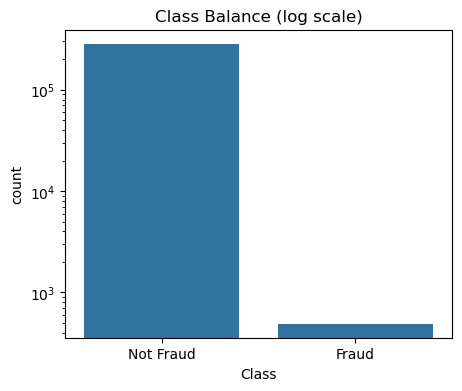

In [4]:
print(df["Class"].value_counts())
print(df["Class"].value_counts(normalize=True) * 100)

plt.figure(figsize=(5, 4))
sns.countplot(x="Class", data=df)
plt.yscale("log")
plt.title("Class Balance (log scale)")
plt.xticks([0, 1], ["Not Fraud", "Fraud"])
plt.show()

In [6]:
X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

### Why Accuracy Lies Here

- A model that always predicts "not fraud" scores over 99.8 percent accuracy while catching zero fraud
- Accuracy alone hides this completely, precision, recall, and F1 do not


In [7]:
baseline_model = LogisticRegression(max_iter=1000)
baseline_model.fit(X_train, y_train)
baseline_preds = baseline_model.predict(X_test)

print("accuracy:", accuracy_score(y_test, baseline_preds))
print(
    classification_report(y_test, baseline_preds, target_names=["Not Fraud", "Fraud"])
)

accuracy: 0.9991573329588147
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00     85295
       Fraud       0.82      0.66      0.73       148

    accuracy                           1.00     85443
   macro avg       0.91      0.83      0.86     85443
weighted avg       1.00      1.00      1.00     85443



c:\Users\IyadM\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Class Weighting

- Tells the model to treat a mistake on the minority class as more costly than a mistake on the majority class
- No resampling needed, the data itself is untouched


In [8]:
cw_model = LogisticRegression(max_iter=1000, class_weight="balanced")
cw_model.fit(X_train, y_train)
cw_preds = cw_model.predict(X_test)

print(classification_report(y_test, cw_preds, target_names=["Not Fraud", "Fraud"]))

              precision    recall  f1-score   support

   Not Fraud       1.00      0.97      0.99     85295
       Fraud       0.05      0.89      0.10       148

    accuracy                           0.97     85443
   macro avg       0.53      0.93      0.54     85443
weighted avg       1.00      0.97      0.98     85443



c:\Users\IyadM\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Random Oversampling

- Duplicates minority class rows until the classes are balanced
- Simple, but the model can overfit on the exact same repeated examples


In [9]:
ros = RandomOverSampler(random_state=42)
X_ros, y_ros = ros.fit_resample(X_train, y_train)
print("after oversampling:", np.bincount(y_ros))

ros_model = LogisticRegression(max_iter=1000)
ros_model.fit(X_ros, y_ros)
ros_preds = ros_model.predict(X_test)

print(classification_report(y_test, ros_preds, target_names=["Not Fraud", "Fraud"]))

after oversampling: [199020 199020]
              precision    recall  f1-score   support

   Not Fraud       1.00      0.98      0.99     85295
       Fraud       0.06      0.88      0.11       148

    accuracy                           0.98     85443
   macro avg       0.53      0.93      0.55     85443
weighted avg       1.00      0.98      0.99     85443



c:\Users\IyadM\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### SMOTE

- Synthetic Minority Oversampling Technique
- Creates new synthetic minority examples instead of duplicating real ones
- Each synthetic point is interpolated between a minority sample and one of its nearest minority neighbors


In [12]:
smote = SMOTE(random_state=42)
X_sm, y_sm = smote.fit_resample(X_train, y_train)
print("after SMOTE:", np.bincount(y_sm))

sm_model = LogisticRegression(max_iter=1000)
sm_model.fit(X_sm, y_sm)
sm_preds = sm_model.predict(X_test)

print(classification_report(y_test, sm_preds, target_names=["Not Fraud", "Fraud"]))

after SMOTE: [199020 199020]
              precision    recall  f1-score   support

   Not Fraud       1.00      0.99      0.99     85295
       Fraud       0.13      0.85      0.22       148

    accuracy                           0.99     85443
   macro avg       0.56      0.92      0.61     85443
weighted avg       1.00      0.99      0.99     85443



### Random Undersampling

- Removes majority class rows until the classes are balanced
- Fast and simple, but risks throwing away useful majority-class information


In [13]:
rus = RandomUnderSampler(random_state=42)
X_rus, y_rus = rus.fit_resample(X_train, y_train)
print("after undersampling:", np.bincount(y_rus))

rus_model = LogisticRegression(max_iter=1000)
rus_model.fit(X_rus, y_rus)
rus_preds = rus_model.predict(X_test)

print(classification_report(y_test, rus_preds, target_names=["Not Fraud", "Fraud"]))

after undersampling: [344 344]
              precision    recall  f1-score   support

   Not Fraud       1.00      0.97      0.99     85295
       Fraud       0.05      0.88      0.10       148

    accuracy                           0.97     85443
   macro avg       0.53      0.93      0.54     85443
weighted avg       1.00      0.97      0.98     85443



### Comparing Results

- Compare precision, recall, and F1 across every approach on the same held-out test set
- The real judgment call is the precision/recall tradeoff, there is rarely a single overall winner


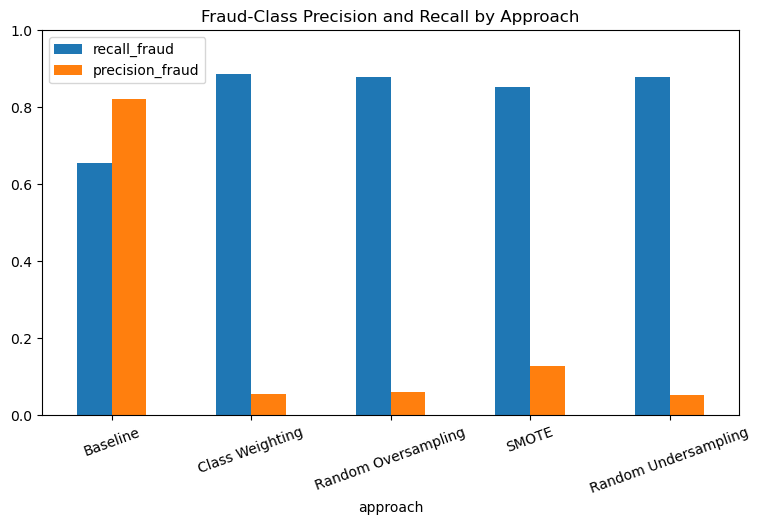

,approach,recall_fraud,precision_fraud
0,Baseline,0.655405,0.822034
1,Class Weighting,0.885135,0.054244
2,Random Oversampling,0.878378,0.061033
3,SMOTE,0.851351,0.128049
4,Random Undersampling,0.878378,0.053520


In [14]:
results = pd.DataFrame(
    {
        "approach": [
            "Baseline",
            "Class Weighting",
            "Random Oversampling",
            "SMOTE",
            "Random Undersampling",
        ],
        "recall_fraud": [
            classification_report(y_test, baseline_preds, output_dict=True)["1"][
                "recall"
            ],
            classification_report(y_test, cw_preds, output_dict=True)["1"]["recall"],
            classification_report(y_test, ros_preds, output_dict=True)["1"]["recall"],
            classification_report(y_test, sm_preds, output_dict=True)["1"]["recall"],
            classification_report(y_test, rus_preds, output_dict=True)["1"]["recall"],
        ],
        "precision_fraud": [
            classification_report(y_test, baseline_preds, output_dict=True)["1"][
                "precision"
            ],
            classification_report(y_test, cw_preds, output_dict=True)["1"]["precision"],
            classification_report(y_test, ros_preds, output_dict=True)["1"][
                "precision"
            ],
            classification_report(y_test, sm_preds, output_dict=True)["1"]["precision"],
            classification_report(y_test, rus_preds, output_dict=True)["1"][
                "precision"
            ],
        ],
    }
)
results.set_index("approach").plot(kind="bar", figsize=(9, 5))
plt.title("Fraud-Class Precision and Recall by Approach")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

results

## Part 3: Transformers for Text Classification


### Setup


In [1]:
!pip install -q transformers datasets evaluate accelerate

import numpy as np
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.1 MB/s eta 0:00:00


### Load and Prepare the Data

- Same dataset as the LSTM/GRU sentiment project, Sentiment140
- This time fine-tuning a pretrained transformer instead of training an architecture from scratch


In [2]:
import kagglehub, glob, os

dataset_path = kagglehub.dataset_download("kazanova/sentiment140")
csv_file = glob.glob(os.path.join(dataset_path, "*.csv"))[0]
columns = ["target", "ids", "date", "flag", "user", "text"]
df = pd.read_csv(csv_file, encoding="latin-1", names=columns)
df["target"] = df["target"].map({0: 0, 4: 1})


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


df["clean_text"] = df["text"].apply(clean_text)

SAMPLE_SIZE_PER_CLASS = 3000
df_sampled = (
    df.groupby("target", group_keys=False)
    .apply(lambda x: x.sample(min(len(x), SAMPLE_SIZE_PER_CLASS), random_state=42))
    .reset_index(drop=True)
)

X_train, X_test, y_train, y_test = train_test_split(
    df_sampled["clean_text"],
    df_sampled["target"],
    test_size=0.2,
    random_state=42,
    stratify=df_sampled["target"],
)
print("train size:", len(X_train), "test size:", len(X_test))

Using Colab cache for faster access to the 'sentiment140' dataset.
train size: 4800 test size: 1200


/tmp/ipykernel_3039/274441698.py:25: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(len(x), SAMPLE_SIZE_PER_CLASS), random_state=42))


### Tokenizing for a Transformer

- A transformer's tokenizer does more than the word-level Tokenizer used for the LSTM/GRU model
- It splits text into subword pieces, not just whole words, so it can handle a word it has never seen by breaking it into familiar chunks
- input_ids: the actual sequence of token id numbers the model reads
- attention_mask: marks real tokens as 1 and padding as 0, so the model knows to ignore the padding
- A `[CLS]` token gets added at the very start, its final representation is what the classification head actually reads
- A `[SEP]` token marks the end of the sequence


In [3]:
MODEL_CHECKPOINT = "distilbert-base-uncased"
MAX_LENGTH = 64

tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

example = tokenizer(
    "this movie was great", padding="max_length", truncation=True, max_length=16
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [4]:
example

{'input_ids': [101, 2023, 3185, 2001, 2307, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}

In [5]:
print("tokens:", tokenizer.convert_ids_to_tokens(example["input_ids"]))

tokens: ['[CLS]', 'this', 'movie', 'was', 'great', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']


In [7]:
lst = [1, 2, 3]
lst

[1, 2, 3]

In [8]:
np.array(lst)

array([1, 2, 3])

In [9]:
def tokenize_batch(texts):
    return tokenizer(
        list(texts),
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt",
    )


train_encodings = tokenize_batch(X_train)
test_encodings = tokenize_batch(X_test)

In [10]:
import torch


class SentimentDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item


train_dataset = SentimentDataset(train_encodings, y_train)
test_dataset = SentimentDataset(test_encodings, y_test)

### Loading a Pretrained Model with a Classification Head

- `AutoModelForSequenceClassification` loads DistilBERT's pretrained transformer layers, plus a new classification head on top
- The pretrained layers already understand general language patterns from massive pretraining on unrelated text
- Only the new head, and some adjustment of the existing layers, needs to happen during fine-tuning
- `num_labels` tells the head how many output classes to produce, 2 here for positive versus negative


In [11]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT, num_labels=2
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### Setting Up Training

- `TrainingArguments` controls how the training loop behaves
- learning_rate: how big each weight update step is, transformers typically fine-tune with a small rate like 2e-5, since the pretrained weights already work well and only need a gentle nudge
- num_train_epochs: how many full passes over the training data
- per_device_train_batch_size: how many examples get processed together in one step
- weight_decay: a small penalty on large weights, helps reduce overfitting
- `Trainer` bundles the model, the arguments, and the datasets into one object that runs the actual loop


In [12]:
args = TrainingArguments(
    output_dir="distilbert-sentiment",
    eval_strategy="epoch",
    learning_rate=2e-5,
    num_train_epochs=3,
    weight_decay=0.01,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    processing_class=tokenizer,
)

In [13]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,No log,0.458930
2,0.465146,0.505103
3,0.465146,0.542862


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=900, training_loss=0.3796631368001302, metrics={'train_runtime': 103.3288, 'train_samples_per_second': 139.361, 'train_steps_per_second': 8.71, 'total_flos': 238441317580800.0, 'train_loss': 0.3796631368001302, 'epoch': 3.0})

### Evaluate

- Accuracy alone is still not enough, look at precision, recall, F1, and the confusion matrix


              precision    recall  f1-score   support

    Negative       0.78      0.80      0.79       600
    Positive       0.79      0.78      0.79       600

    accuracy                           0.79      1200
   macro avg       0.79      0.79      0.79      1200
weighted avg       0.79      0.79      0.79      1200



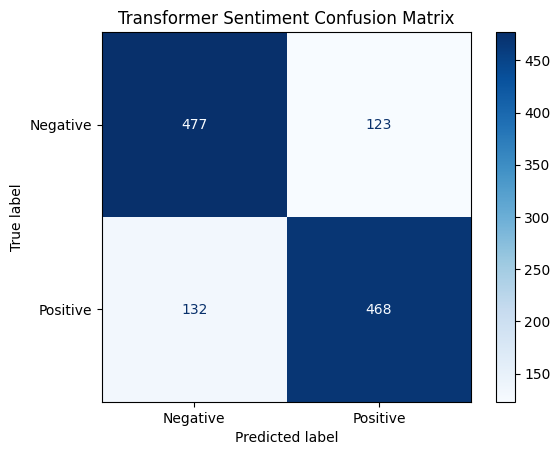

In [16]:
predictions = trainer.predict(test_dataset)
preds = predictions.predictions.argmax(axis=-1)

print(classification_report(y_test, preds, target_names=["Negative", "Positive"]))

cm = confusion_matrix(y_test, preds)
disp = ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"])
disp.plot(cmap="Blues")
plt.title("Transformer Sentiment Confusion Matrix")
plt.show()

### Demo

- Same idea as before, a plain function: raw text in, sentiment out


In [ ]:
def predict_sentiment(text, model=model, tokenizer=tokenizer, max_length=MAX_LENGTH):
    cleaned = clean_text(text)
    inputs = tokenizer(
        cleaned,
        return_tensors="pt",
        padding="max_length",
        truncation=True,
        max_length=max_length,
    )
    inputs = {k: v.to(model.device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model(**inputs)
    probs = torch.softmax(outputs.logits, dim=-1)[0]
    label = "Positive" if probs[1] > probs[0] else "Negative"
    confidence = float(max(probs))
    return label, confidence


examples = [
    "I absolutely hated the new update, works so much better now!",
    "This is the worst customer service I've ever dealt with.",
]
for text in examples:
    label, confidence = predict_sentiment(text)
    print(f"{text!r} -> {label} ({confidence:.2%} confidence)")

'I absolutely hated the new update, works so much better now!' -> Negative (97.08% confidence)
"This is the worst customer service I've ever dealt with." -> Negative (98.47% confidence)


### From LSTM/GRU to Transformer, What Changed

- The LSTM/GRU project trained an embedding layer and a recurrent layer entirely from scratch, learning everything from just the sampled tweets
- The transformer starts from weights already trained on a huge amount of text, only the classification head starts from scratch
- An RNN reads tokens one at a time in order, a transformer looks at the whole sequence at once through self-attention
- This is a big part of why a fine-tuned transformer often reaches strong accuracy faster and with less task-specific data


## Summary

- SQL commands split into five categories: DDL for structure, DML for changing data, DQL for reading data, plus DCL and TCL for permissions and transactions
- Imbalanced data makes accuracy misleading, class weighting, oversampling, SMOTE, and undersampling each trade precision against recall differently
- Fine-tuning a pretrained transformer swaps training an architecture from scratch for adapting weights that already understand language, using a tokenizer, a classification head, and a standard training loop
